# Tema 6 · Dependencia no lineal y modelización de colas con cópulas — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) Casos 1 y 2 y la tabla de Excel, familias de cópulas, dependencia de cola y conversión τ–θ, (B) límites de la correlación de Pearson,
(C) la simulación de la práctica de R (Gaussiana frente a Clayton rotada) y qué recargo implica cada cola, (D) generación aleatoria de cópulas escrita desde cero y su validación,
(E) el ejercicio de ajuste (muestra de n = 1.500, pseudo-observaciones, MLE, AIC/BIC, bondad de ajuste Sn, cola y capital), (F) cuatro módulos de SCR y n riesgos.
**Nota sobre los datos:** el fichero `muestra_copula_t15.csv` de las diapositivas no se entregó con ellas; se **regenera** aquí con el proceso que describen
(cópula t con ν = 15 y ρ = 0,70, X lognormal(ln 12; 0,45), Y gamma(3; 4), ruido multiplicativo lognormal del 10 %, n = 1.500) y se guarda como `t6_muestra_copula_t15.csv`;
Excel y R usan exactamente ese fichero. La semilla (28) se eligió entre 119 para que τ̂, ρ̂ y ν̂ se parezcan a los de las diapositivas; con otras semillas el AIC puede no distinguir la t de la Gaussiana (ver la advertencia de las diapositivas). Todo está programado con `numpy`/`scipy` (sin paquetes de cópulas) para que cada fórmula sea visible.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize, special, integrate
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
z995 = stats.norm.ppf(0.995)

def scr_gauss(S, P):                       # fórmula estándar: raíz de S'PS
    S = np.asarray(S, float); return float(np.sqrt(S @ np.asarray(P, float) @ S))

# dependencia de cola y conversión tau <-> parámetro
def lam_clayton(th): return 2.0 ** (-1.0 / th)
def lam_gumbel(th):  return 2.0 - 2.0 ** (1.0 / th)
def lam_t(rho, nu):  return 2.0 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)
def debye1(th):      return integrate.quad(lambda t: t / np.expm1(t), 0, th)[0] / th
def tau_frank(th):   return 1 - 4 * (1 - debye1(th)) / th
def th_frank(tau):   return optimize.brentq(lambda th: tau_frank(th) - tau, 1e-6, 60)
def rho_from_tau(t): return np.sin(np.pi * t / 2)
def th_clayton(t):   return 2 * t / (1 - t)
def th_gumbel(t):    return 1 / (1 - t)

## (A) Casos 1 y 2, sensibilidad y perfil de cola de cada familia
Caso 1: $SCR=\sqrt{SCR_{mkt}^2+SCR_{uw}^2+2\rho\,SCR_{mkt}SCR_{uw}}$ y recargo del 13 % por cola. Caso 2: $\lambda_L=2^{-1/\theta}$ (Clayton).

In [2]:
m, u, rho, rec = 40, 30, 0.25, 0.13
scr = scr_gauss([m, u], [[1, rho], [rho, 1]])
print(f"CASO 1  SCR estándar = {scr:.4f}   beneficio de diversificación = {m+u-scr:.4f} ({(m+u-scr)/(m+u):.1%} de la suma)")
print(f"        SCR con recargo de cola = {scr*(1+rec):.4f}   capital adicional = {scr*rec:.4f} M€")
sens = pd.DataFrame({"rho": [0, .25, .5, .75]})
sens["SCR_estandar"] = [scr_gauss([m, u], [[1, r], [r, 1]]) for r in sens.rho]
sens["SCR_mas_13%"] = sens.SCR_estandar * 1.13; sens["adicional"] = sens.SCR_estandar * .13
sens["adicional/suma"] = sens.adicional / (m + u)
print(sens.round(4).to_string(index=False))
th2 = 1.5
print(f"\nCASO 2  lambda_L = 2^(-1/{th2}) = {lam_clayton(th2):.4f}  ->  {lam_clayton(th2):.1%} de contagio asintótico")
print(f"        tau = theta/(theta+2) = {th2/(th2+2):.4f}; rho Gaussiana con igual tau = {rho_from_tau(th2/(th2+2)):.4f}")

print("\nθ de cada familia con τ = 0,5 y su cola:")
tau0 = .5
rows = [("Gaussiana", rho_from_tau(tau0), 0, 0), ("t (ν=15)", rho_from_tau(tau0), lam_t(rho_from_tau(tau0), 15), lam_t(rho_from_tau(tau0), 15)),
        ("t (ν=4)", rho_from_tau(tau0), lam_t(rho_from_tau(tau0), 4), lam_t(rho_from_tau(tau0), 4)),
        ("Clayton", th_clayton(tau0), lam_clayton(th_clayton(tau0)), 0), ("Gumbel", th_gumbel(tau0), 0, lam_gumbel(th_gumbel(tau0))), ("Frank", th_frank(tau0), 0, 0)]
print(pd.DataFrame(rows, columns=["familia", "parametro", "lambda_L", "lambda_U"]).round(4).to_string(index=False))
print("\nθ = 2 (gráfico de la diapositiva 15): Clayton λ_L =", round(lam_clayton(2), 4), " Gumbel λ_U =", round(lam_gumbel(2), 4), " Frank 0 / 0")

CASO 1  SCR estándar = 55.6776   beneficio de diversificación = 14.3224 (20.5% de la suma)
        SCR con recargo de cola = 62.9157   capital adicional = 7.2381 M€
 rho  SCR_estandar  SCR_mas_13%  adicional  adicional/suma
0.00       50.0000      56.5000     6.5000          0.0929
0.25       55.6776      62.9157     7.2381          0.1034
0.50       60.8276      68.7352     7.9076          0.1130
0.75       65.5744      74.0991     8.5247          0.1218

CASO 2  lambda_L = 2^(-1/1.5) = 0.6300  ->  63.0% de contagio asintótico
        tau = theta/(theta+2) = 0.4286; rho Gaussiana con igual tau = 0.6235

θ de cada familia con τ = 0,5 y su cola:
  familia  parametro  lambda_L  lambda_U
Gaussiana     0.7071    0.0000    0.0000
 t (ν=15)     0.7071    0.1170    0.1170
  t (ν=4)     0.7071    0.3968    0.3968
  Clayton     2.0000    0.7071    0.0000
   Gumbel     2.0000    0.0000    0.5858
    Frank     5.7363    0.0000    0.0000

θ = 2 (gráfico de la diapositiva 15): Clayton λ_L = 0.7071 

## (B) Los límites de la correlación de Pearson, con números
1. $Y=X^2$: dependencia determinista y $\rho=0$. 2. Pearson **no es invariante** a transformaciones monótonas (Spearman y τ sí).

In [3]:
X = rng.standard_normal(500_000); Y = X ** 2
print(f"1) Y = X²: Pearson = {np.corrcoef(X, Y)[0,1]:+.4f}  Spearman = {stats.spearmanr(X, Y)[0]:+.4f}  (dependencia exacta, medidas ≈ 0)")
rho_g = .7; Z = rng.standard_normal((400_000, 2)); Z[:, 1] = rho_g * Z[:, 0] + np.sqrt(1 - rho_g ** 2) * Z[:, 1]
print(f"2) (Z1,Z2) normales ρ=0,7: Pearson = {np.corrcoef(Z.T)[0,1]:.4f}; tras exp(): Pearson = {np.corrcoef(np.exp(Z).T)[0,1]:.4f} "
      f"(teórico (e^ρ−1)/(e−1) = {(np.exp(rho_g)-1)/(np.e-1):.4f}); τ antes {stats.kendalltau(Z[:5000,0], Z[:5000,1])[0]:.4f} y después {stats.kendalltau(np.exp(Z[:5000,0]), np.exp(Z[:5000,1]))[0]:.4f}")

1) Y = X²: Pearson = +0.0023  Spearman = -0.0002  (dependencia exacta, medidas ≈ 0)
2) (Z1,Z2) normales ρ=0,7: Pearson = 0.6982; tras exp(): Pearson = 0.5851 (teórico (e^ρ−1)/(e−1) = 0.5900); τ antes 0.4912 y después 0.4912


## (D, parte 1) Simuladores escritos desde cero
Cholesky para la Gaussiana y la t; Marshall–Olkin (fragilidad común) para Clayton y Gumbel; distribución condicional (Rosenblatt inverso) para Clayton y Frank.

In [4]:
def r_gauss(n, rho, rng=rng):
    z = rng.standard_normal((n, 2)) @ np.linalg.cholesky(np.array([[1, rho], [rho, 1]])).T; return stats.norm.cdf(z)
def r_t(n, rho, nu, rng=rng):
    z = rng.standard_normal((n, 2)) @ np.linalg.cholesky(np.array([[1, rho], [rho, 1]])).T
    return stats.t.cdf(z / np.sqrt(rng.chisquare(nu, n) / nu)[:, None], nu)
def r_clayton(n, th, d=2, rng=rng):                       # Marshall-Olkin, V ~ Gamma(1/θ)
    V = rng.gamma(1 / th, size=(n, 1)); E = rng.exponential(size=(n, d)); return (1 + E / V) ** (-1 / th)
def r_gumbel(n, th, d=2, rng=rng):                        # V estable positiva de índice 1/θ
    a = 1 / th; Th = rng.uniform(0, np.pi, n); W = rng.exponential(size=n)
    V = (np.sin(a * Th) / np.sin(Th) ** (1 / a) * (np.sin((1 - a) * Th) / W) ** ((1 - a) / a))[:, None]
    E = rng.exponential(size=(n, d)); return np.exp(-(E / V) ** (1 / th))
def r_clayton_cond(n, th, rng=rng):
    u, w = rng.uniform(size=n), rng.uniform(size=n); return np.c_[u, (1 + u ** (-th) * (w ** (-th / (1 + th)) - 1)) ** (-1 / th)]
def r_frank_cond(n, th, rng=rng):
    u, w = rng.uniform(size=n), rng.uniform(size=n); return np.c_[u, -np.log1p(w * np.expm1(-th) / (w + (1 - w) * np.exp(-th * u))) / th]
def rot(U): return 1 - U

def lam_emp(U, q, upper=True):
    a, b = U[:, 0], U[:, 1]
    return np.mean((a > q) & (b > q)) / np.mean(a > q) if upper else np.mean((a < 1 - q) & (b < 1 - q)) / np.mean(a < 1 - q)

N = 400_000; tau0 = .5
sims = {"Gaussiana": r_gauss(N, rho_from_tau(tau0)), "t ν=4": r_t(N, rho_from_tau(tau0), 4), "Clayton (MO)": r_clayton(N, th_clayton(tau0)),
        "Clayton (condicional)": r_clayton_cond(N, th_clayton(tau0)), "Gumbel (MO)": r_gumbel(N, th_gumbel(tau0)), "Frank (condicional)": r_frank_cond(N, th_frank(tau0))}
rows = []
for k, U in sims.items():
    ks = max(stats.kstest(U[:, 0], "uniform").statistic, stats.kstest(U[:, 1], "uniform").statistic)
    rows.append((k, ks, stats.kendalltau(U[:20000, 0], U[:20000, 1])[0], lam_emp(U, .99, False), lam_emp(U, .99, True)))
print("Validación con 400.000 pares: marginales U(0,1) (KS), τ empírica (objetivo 0,5) y P(V>q|U>q) con q=0,99")
print(pd.DataFrame(rows, columns=["simulador", "KS marginal", "tau emp.", "λ_L(0,99) emp.", "λ_U(0,99) emp."]).round(4).to_string(index=False))
print(f"Valores asintóticos: Clayton λ_L={lam_clayton(th_clayton(.5)):.3f}, Gumbel λ_U={lam_gumbel(th_gumbel(.5)):.3f}, t(ν=4) λ={lam_t(rho_from_tau(.5),4):.3f}, Gaussiana 0, Frank 0 (el valor a q=0,99 es menor: la convergencia es lenta)")

Validación con 400.000 pares: marginales U(0,1) (KS), τ empírica (objetivo 0,5) y P(V>q|U>q) con q=0,99
            simulador  KS marginal  tau emp.  λ_L(0,99) emp.  λ_U(0,99) emp.
            Gaussiana       0.0012    0.5034          0.2791          0.2637
                t ν=4       0.0013    0.4990          0.4217          0.4355
         Clayton (MO)       0.0014    0.4973          0.7108          0.0329
Clayton (condicional)       0.0020    0.5102          0.7111          0.0267
          Gumbel (MO)       0.0024    0.4980          0.1543          0.5901
  Frank (condicional)       0.0016    0.5033          0.0558          0.0511
Valores asintóticos: Clayton λ_L=0.707, Gumbel λ_U=0.586, t(ν=4) λ=0.397, Gaussiana 0, Frank 0 (el valor a q=0,99 es menor: la convergencia es lenta)


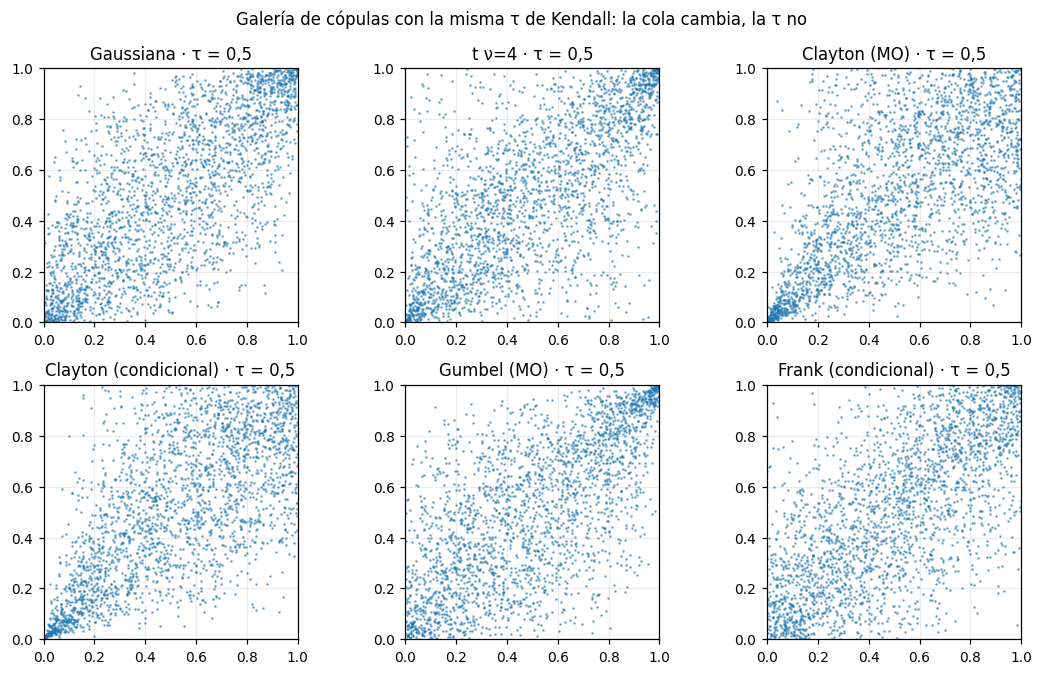

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(10, 6.2))
for ax, (k, U) in zip(axs.ravel(), sims.items()):
    ax.plot(U[:2500, 0], U[:2500, 1], ".", ms=1.6, alpha=.5); ax.set_title(k + " · τ = 0,5"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
fig.suptitle("Galería de cópulas con la misma τ de Kendall: la cola cambia, la τ no"); fig.tight_layout(); plt.show()

## (C) Práctica de R del Caso 1: Gaussiana frente a Clayton rotada con la misma τ
Pérdidas normales con $SCR_i=VaR_{99,5\%}$ marginal; se agrega con cada cópula y se compara el VaR 99,5 % de la suma. Primero con $n=10^5$ como en las diapositivas y después con $2ot10^6$ para reducir el error de muestreo.

In [6]:
tau_g = 2 / np.pi * np.arcsin(rho); th_c = th_clayton(tau_g)
print(f"τ de Kendall de la Gaussiana(0,25) = {tau_g:.6f}   θ de Clayton con esa τ = {th_c:.6f}   λ_U de la Clayton rotada = {lam_clayton(th_c):.4f}")
sd_m, sd_u = m / z995, u / z995
def perdida(U): return stats.norm.ppf(U[:, 0]) * sd_m + stats.norm.ppf(U[:, 1]) * sd_u
def var_tvar(L, q=.995):
    v = np.quantile(L, q); return v, L[L >= v].mean()
for n_sim, sd in ((100_000, 123), (2_000_000, 7)):
    g = np.random.default_rng(sd)
    Lg = perdida(r_gauss(n_sim, rho, g)); Lc = perdida(rot(r_clayton(n_sim, th_c, rng=g))); Lcn = perdida(r_clayton(n_sim, th_c, rng=g))
    (vg, tg), (vc, tc), (vn, tn) = var_tvar(Lg), var_tvar(Lc), var_tvar(Lcn)
    print(f"\nn = {n_sim:,}:  VaR99,5  Gaussiana = {vg:.2f}   Clayton rotada = {vc:.2f} ({vc/vg-1:+.1%})   Clayton sin rotar = {vn:.2f} ({vn/vg-1:+.1%})")
    print(f"             TVaR99,5 Gaussiana = {tg:.2f}   Clayton rotada = {tc:.2f} ({tc/tg-1:+.1%})")
print(f"\nFórmula estándar (Caso 1) = {scr:.2f} M€; con +13 % = {scr*1.13:.2f} M€.")

τ de Kendall de la Gaussiana(0,25) = 0.160861   θ de Clayton con esa τ = 0.383396   λ_U de la Clayton rotada = 0.1640

n = 100,000:  VaR99,5  Gaussiana = 55.80   Clayton rotada = 62.20 (+11.5%)   Clayton sin rotar = 52.31 (-6.3%)
             TVaR99,5 Gaussiana = 62.39   Clayton rotada = 71.38 (+14.4%)



n = 2,000,000:  VaR99,5  Gaussiana = 55.69   Clayton rotada = 62.00 (+11.3%)   Clayton sin rotar = 51.93 (-6.8%)
             TVaR99,5 Gaussiana = 62.57   Clayton rotada = 70.76 (+13.1%)

Fórmula estándar (Caso 1) = 55.68 M€; con +13 % = 62.92 M€.


In [7]:
# ¿Qué cola haría falta para el +13 %? θ de la Clayton rotada con números aleatorios comunes (u,w fijos): el VaR es función continua de θ
g = np.random.default_rng(99); uu, ww = g.uniform(size=1_000_000), g.uniform(size=1_000_000)
def var_rot_clayton(th):
    v = (1 + uu ** (-th) * (ww ** (-th / (1 + th)) - 1)) ** (-1 / th); return np.quantile(perdida(rot(np.c_[uu, v])), .995)
th13 = optimize.brentq(lambda th: var_rot_clayton(th) / scr - 1.13, 0.05, 6)
print(f"θ de la Clayton rotada para un recargo del 13 %: θ = {th13:.3f}  ->  τ = {th13/(th13+2):.3f}, λ_U = {lam_clayton(th13):.3f}")
ths = [.2, .384, .6, 1, 1.5, 2, 3]
print("Curva recargo(θ) respecto a la fórmula estándar (VaR Gaussiana exacto = 55,68):")
print(pd.DataFrame({"theta": ths, "tau": [t / (t + 2) for t in ths], "lambda_U": [lam_clayton(t) for t in ths], "recargo": [var_rot_clayton(t) / scr - 1 for t in ths]}).round(4).to_string(index=False))

θ de la Clayton rotada para un recargo del 13 %: θ = 0.447  ->  τ = 0.183, λ_U = 0.212
Curva recargo(θ) respecto a la fórmula estándar (VaR Gaussiana exacto = 55,68):


 theta    tau  lambda_U  recargo
 0.200 0.0909    0.0312   0.0321
 0.384 0.1611    0.1645   0.1114
 0.600 0.2308    0.3150   0.1642
 1.000 0.3333    0.5000   0.2099
 1.500 0.4286    0.6300   0.2320
 2.000 0.5000    0.7071   0.2406
 3.000 0.6000    0.7937   0.2489


## (E) Ejercicio de ajuste de cópulas a una muestra
La muestra se regenera (ver nota inicial). Pasos: (1–2) descriptivos y pseudo-observaciones; (3) MLE de Gaussiana, t, Clayton (y rotada), Gumbel y Frank; (4) log-verosimilitud, AIC, BIC y bondad de ajuste $S_n$ por bootstrap paramétrico; (5) $\lambda_L,\lambda_U$ implícitos y empíricos; (6) marginales, $10^6$ pares y VaR/TVaR 99,5 % de $X+Y$; (7) conclusión.

In [8]:
n = 1500; rho_true, nu_true = .70, 15
g = np.random.default_rng(28)
Ut = r_t(n, rho_true, nu_true, g)
X0 = stats.lognorm.ppf(Ut[:, 0], s=.45, scale=12); Y0 = stats.gamma.ppf(Ut[:, 1], a=3, scale=4)
Xn = X0 * np.exp(.10 * g.standard_normal(n)); Yn = Y0 * np.exp(.10 * g.standard_normal(n))      # ruido multiplicativo lognormal del 10 %
pd.DataFrame({"obs": np.arange(1, n + 1), "X_perdida_mercado": Xn.round(4), "Y_siniestralidad": Yn.round(4)}).to_csv("t6_muestra_copula_t15.csv", index=False)
dat = pd.read_csv("t6_muestra_copula_t15.csv"); X, Y = dat.X_perdida_mercado.to_numpy(), dat.Y_siniestralidad.to_numpy()
print(dat[["X_perdida_mercado", "Y_siniestralidad"]].describe().round(3).T[["mean", "std", "min", "50%", "max"]].to_string())
print(f"\nPearson = {np.corrcoef(X, Y)[0,1]:.3f}  Spearman = {stats.spearmanr(X, Y)[0]:.3f}  Kendall = {stats.kendalltau(X, Y)[0]:.3f}   (verdad sin ruido: τ = {2/np.pi*np.arcsin(rho_true):.3f})")
Uh = np.c_[stats.rankdata(X), stats.rankdata(Y)] / (n + 1)             # pseudo-observaciones
print("pseudo-observaciones: mín =", Uh.min().round(5), " máx =", Uh.max().round(5))

                     mean    std    min     50%     max
X_perdida_mercado  13.281  6.359  2.182  12.047  45.868
Y_siniestralidad   11.904  6.873  0.686  10.503  42.967

Pearson = 0.663  Spearman = 0.662  Kendall = 0.478   (verdad sin ruido: τ = 0.494)
pseudo-observaciones: mín = 0.00067  máx = 0.99933


In [9]:
# log-densidades de cada cópula y funciones de distribución C(u,v) para la bondad de ajuste
def ll_gauss(U, r):
    x, y = stats.norm.ppf(U[:, 0]), stats.norm.ppf(U[:, 1]); return -.5 * np.log1p(-r * r) - (r * r * (x * x + y * y) - 2 * r * x * y) / (2 * (1 - r * r))
def ll_t(U, r, nu):
    x, y = stats.t.ppf(U[:, 0], nu), stats.t.ppf(U[:, 1], nu)
    l2 = special.gammaln((nu + 2) / 2) - special.gammaln(nu / 2) - np.log(nu * np.pi) - .5 * np.log1p(-r * r) - (nu + 2) / 2 * np.log1p((x * x - 2 * r * x * y + y * y) / (nu * (1 - r * r)))
    return l2 - stats.t.logpdf(x, nu) - stats.t.logpdf(y, nu)
def ll_clayton(U, th):
    a, b = U[:, 0], U[:, 1]; return np.log1p(th) - (1 + th) * (np.log(a) + np.log(b)) - (2 + 1 / th) * np.log(a ** -th + b ** -th - 1)
def ll_gumbel(U, th):
    a, b = -np.log(U[:, 0]), -np.log(U[:, 1]); A = a ** th + b ** th
    return -A ** (1 / th) + a + b + (th - 1) * (np.log(a) + np.log(b)) + (2 / th - 2) * np.log(A) + np.log1p((th - 1) * A ** (-1 / th))
def ll_frank(U, th):
    a, b = U[:, 0], U[:, 1]; e = 1 - np.exp(-th)
    return np.log(th * e) - th * (a + b) - 2 * np.log(e - (1 - np.exp(-th * a)) * (1 - np.exp(-th * b)))

def C_clayton(a, b, th): return (a ** -th + b ** -th - 1) ** (-1 / th)
def C_gumbel(a, b, th): return np.exp(-((-np.log(a)) ** th + (-np.log(b)) ** th) ** (1 / th))
def C_frank(a, b, th): return -np.log1p((np.exp(-th * a) - 1) * (np.exp(-th * b) - 1) / (np.exp(-th) - 1)) / th
def C_gauss(a, b, r): return stats.multivariate_normal(cov=[[1, r], [r, 1]]).cdf(np.c_[stats.norm.ppf(a), stats.norm.ppf(b)])
def fd(C, a, b, th, h=1e-4): return (C(a + h, b + h, th) - C(a + h, b - h, th) - C(a - h, b + h, th) + C(a - h, b - h, th)) / (4 * h * h)
a0, b0 = np.array([.3, .8]), np.array([.6, .9]); P0 = np.c_[a0, b0]
for nm, C, ll, th in (("Clayton", C_clayton, ll_clayton, 1.7), ("Gumbel", C_gumbel, ll_gumbel, 1.8), ("Frank", C_frank, ll_frank, 5.3), ("Gaussiana", C_gauss, ll_gauss, .6)):
    print(f"densidad {nm:10s}: analítica {np.exp(ll(P0, th)).round(5)}   diferencias finitas {fd(C, a0, b0, th).round(5)}")

densidad Clayton   : analítica [0.90514 1.77248]   diferencias finitas [0.90514 1.77248]
densidad Gumbel    : analítica [0.98409 2.00168]   diferencias finitas [0.98409 2.00168]
densidad Frank     : analítica [0.83061 2.03953]   diferencias finitas [0.83061 2.03953]
densidad Gaussiana : analítica [1.0032 1.7739]   diferencias finitas [1.0032 1.7739]


In [10]:
# MLE (pseudo-verosimilitud: se usan los rangos, no las marginales)
def mle1(ll, lo, hi, U=Uh):
    r = optimize.minimize_scalar(lambda t: -ll(U, t).sum(), bounds=(lo, hi), method="bounded", options={"xatol": 1e-9}); return r.x, -r.fun
def mle_t(U=Uh):
    r = optimize.minimize(lambda p: -ll_t(U, p[0], p[1]).sum(), x0=[.7, 10], bounds=[(.01, .99), (2.2, 150)], method="L-BFGS-B"); return r.x, -r.fun
fits = {}
r_, l_ = mle1(ll_gauss, .01, .99); fits["Gaussiana"] = dict(par=(r_,), ll=l_, k=1)
(r_, nu_), l_ = mle_t(); fits["t-Student"] = dict(par=(r_, nu_), ll=l_, k=2)
th_, l_ = mle1(ll_clayton, .01, 20); fits["Clayton"] = dict(par=(th_,), ll=l_, k=1)
th_, l_ = mle1(ll_clayton, .01, 20, 1 - Uh); fits["Clayton rotada"] = dict(par=(th_,), ll=l_, k=1)
th_, l_ = mle1(ll_gumbel, 1.0001, 20); fits["Gumbel"] = dict(par=(th_,), ll=l_, k=1)
th_, l_ = mle1(ll_frank, .01, 40); fits["Frank"] = dict(par=(th_,), ll=l_, k=1)
lam = {"Gaussiana": (0, 0), "t-Student": (lam_t(*fits["t-Student"]["par"]),) * 2, "Clayton": (lam_clayton(fits["Clayton"]["par"][0]), 0),
       "Clayton rotada": (0, lam_clayton(fits["Clayton rotada"]["par"][0])), "Gumbel": (0, lam_gumbel(fits["Gumbel"]["par"][0])), "Frank": (0, 0)}
tab = pd.DataFrame({k: {"parámetros": ", ".join(f"{p:.3f}" for p in v["par"]), "logLik": v["ll"], "AIC": -2 * v["ll"] + 2 * v["k"], "BIC": -2 * v["ll"] + v["k"] * np.log(n),
                        "λ_L": lam[k][0], "λ_U": lam[k][1]} for k, v in fits.items()}).T
print(tab.to_string(float_format=lambda x: f"{x:,.3f}"))
tau_hat = stats.kendalltau(X, Y)[0]
print(f"\nInversión de τ (τ̂={tau_hat:.4f}):  Gaussiana ρ = {rho_from_tau(tau_hat):.3f};  Clayton θ = {th_clayton(tau_hat):.3f} (MLE {fits['Clayton']['par'][0]:.3f});  Gumbel θ = {th_gumbel(tau_hat):.3f} (MLE {fits['Gumbel']['par'][0]:.3f});  Frank θ = {th_frank(tau_hat):.3f} (MLE {fits['Frank']['par'][0]:.3f})")
print(f"Contraste LR t frente a Gaussiana: 2Δℓ = {2*(fits['t-Student']['ll']-fits['Gaussiana']['ll']):.2f}  (ν̂ = {fits['t-Student']['par'][1]:.1f}); ΔAIC = {tab.loc['Gaussiana','AIC']-tab.loc['t-Student','AIC']:.2f}, ΔBIC = {tab.loc['Gaussiana','BIC']-tab.loc['t-Student','BIC']:.2f}")

                   parámetros  logLik      AIC      BIC   λ_L   λ_U
Gaussiana               0.681 462.772 -923.544 -918.231     0     0
t-Student       0.682, 15.592 468.747 -933.493 -922.867 0.095 0.095
Clayton                 1.189 356.158 -710.315 -705.002 0.558     0
Clayton rotada          1.173 351.953 -701.907 -696.594     0 0.554
Gumbel                  1.799 424.903 -847.806 -842.493     0 0.530
Frank                   5.298 426.086 -850.171 -844.858     0     0

Inversión de τ (τ̂=0.4780):  Gaussiana ρ = 0.682;  Clayton θ = 1.831 (MLE 1.189);  Gumbel θ = 1.916 (MLE 1.799);  Frank θ = 5.350 (MLE 5.298)
Contraste LR t frente a Gaussiana: 2Δℓ = 11.95  (ν̂ = 15.6); ΔAIC = 9.95, ΔBIC = 4.64


In [11]:
# Bondad de ajuste Sn con bootstrap paramétrico (pseudo-observaciones simuladas del modelo ajustado y reestimación en cada réplica)
def Cn_at(U):
    A = (U[:, 0][:, None] >= U[:, 0][None, :]) & (U[:, 1][:, None] >= U[:, 1][None, :]); return A.mean(axis=1)
def pobs(U): return np.c_[stats.rankdata(U[:, 0]), stats.rankdata(U[:, 1])] / (len(U) + 1)
Cdef = {"Gaussiana": lambda U, p: C_gauss(U[:, 0], U[:, 1], p[0]), "Clayton": lambda U, p: C_clayton(U[:, 0], U[:, 1], p[0]),
        "Gumbel": lambda U, p: C_gumbel(U[:, 0], U[:, 1], p[0]), "Frank": lambda U, p: C_frank(U[:, 0], U[:, 1], p[0])}
Sim = {"Gaussiana": lambda n, p, g: r_gauss(n, p[0], g), "Clayton": lambda n, p, g: r_clayton(n, p[0], rng=g), "Gumbel": lambda n, p, g: r_gumbel(n, p[0], rng=g),
       "Frank": lambda n, p, g: r_frank_cond(n, p[0], g)}
Fit = {"Gaussiana": lambda U: (mle1(ll_gauss, .01, .99, U)[0],), "Clayton": lambda U: (mle1(ll_clayton, .01, 20, U)[0],), "Gumbel": lambda U: (mle1(ll_gumbel, 1.0001, 20, U)[0],),
       "Frank": lambda U: (mle1(ll_frank, .01, 40, U)[0],)}
def Sn(U, name, p): return float(np.sum((Cn_at(U) - Cdef[name](U, p)) ** 2))
B = 200; gb = np.random.default_rng(321); gof = {}
for name in ("Gaussiana", "Clayton", "Gumbel", "Frank"):
    p_hat = fits[name]["par"]; s0 = Sn(Uh, name, p_hat); sb = []
    for _ in range(B):
        Ub = pobs(Sim[name](n, p_hat, gb)); pb = Fit[name](Ub); sb.append(Sn(Ub, name, pb))
    gof[name] = (s0, (1 + np.sum(np.array(sb) >= s0)) / (B + 1)); print(f"{name:10s} Sn = {s0:.4f}   p-valor (B={B}) = {gof[name][1]:.3f}")

Gaussiana  Sn = 0.0087   p-valor (B=200) = 0.960


Clayton    Sn = 0.6984   p-valor (B=200) = 0.005


Gumbel     Sn = 0.1123   p-valor (B=200) = 0.005


Frank      Sn = 0.0656   p-valor (B=200) = 0.005


In [12]:
# t-Student: la función de distribución bivariante t es lenta (integración numérica) -> B menor
rt_, nut_ = fits["t-Student"]["par"]
def Ct(U, p): return stats.multivariate_t(shape=[[1, p[0]], [p[0], 1]], df=p[1], seed=5).cdf(np.c_[stats.t.ppf(U[:, 0], p[1]), stats.t.ppf(U[:, 1], p[1])])
s0 = float(np.sum((Cn_at(Uh) - Ct(Uh, (rt_, nut_))) ** 2)); Bt = 25; sb = []
for _ in range(Bt):
    Ub = pobs(r_t(n, rt_, nut_, gb)); pb, _l = mle_t(Ub); sb.append(float(np.sum((Cn_at(Ub) - Ct(Ub, pb)) ** 2)))
gof["t-Student"] = (s0, (1 + np.sum(np.array(sb) >= s0)) / (Bt + 1)); print(f"t-Student  Sn = {s0:.4f}   p-valor (B={Bt}) = {gof['t-Student'][1]:.3f}  (con B=25 la resolución es 1/26)")

t-Student  Sn = 0.0087   p-valor (B=25) = 0.962  (con B=25 la resolución es 1/26)


In [13]:
# Dependencia de cola empírica frente a la del modelo y efecto sobre el VaR/TVaR de X+Y
rn = np.random.default_rng(2027); NS = 1_000_000
def sim_model(name, g, nn=NS):
    p = fits[name]["par"]
    if name == "Gaussiana": return r_gauss(nn, p[0], g)
    if name == "t-Student": return r_t(nn, p[0], p[1], g)
    if name == "Clayton": return r_clayton(nn, p[0], rng=g)
    if name == "Clayton rotada": return rot(r_clayton(nn, p[0], rng=g))
    if name == "Gumbel": return r_gumbel(nn, p[0], rng=g)
    return r_frank_cond(nn, p[0], g)
sx, _, scx = stats.lognorm.fit(X, floc=0); ga, _, gs = stats.gamma.fit(Y, floc=0)
print(f"Marginales ajustadas: X lognormal(μ={np.log(scx):.3f}, σ={sx:.3f}) · Y gamma(forma={ga:.3f}, escala={gs:.3f})   (verdad: μ={np.log(12):.3f}, σ=0,45 / forma 3, escala 4, con ruido del 10 %)")
inv = lambda U: stats.lognorm.ppf(U[:, 0], sx, scale=scx) + stats.gamma.ppf(U[:, 1], ga, scale=gs)
rows = {}; qs = (.90, .95, .99)
rows["Datos"] = [lam_emp(Uh, q) for q in qs] + list(var_tvar(X + Y))
Ut_true = r_t(NS, rho_true, nu_true, rn)
rows["Verdad (t15, ρ=0,70)"] = [lam_emp(Ut_true, q) for q in qs] + list(var_tvar(stats.lognorm.ppf(Ut_true[:, 0], .45, scale=12) + stats.gamma.ppf(Ut_true[:, 1], 3, scale=4)))
for name in fits:
    U = sim_model(name, rn); rows[name] = [lam_emp(U, q) for q in qs] + list(var_tvar(inv(U)))
res = pd.DataFrame(rows, index=["P(V>q|U>q) q=.90", "q=.95", "q=.99", "VaR 99,5 %", "TVaR 99,5 %"]).T
print(res.to_string(float_format=lambda x: f"{x:,.3f}"))
vt = res.loc["t-Student", "VaR 99,5 %"]
print("\nDiferencia del VaR 99,5 % frente a la cópula t ajustada (%):"); print(((res["VaR 99,5 %"] / vt - 1) * 100).round(2).to_string())

Marginales ajustadas: X lognormal(μ=2.481, σ=0.458) · Y gamma(forma=2.968, escala=4.011)   (verdad: μ=2.485, σ=0,45 / forma 3, escala 4, con ruido del 10 %)


                      P(V>q|U>q) q=.90  q=.95  q=.99  VaR 99,5 %  TVaR 99,5 %
Datos                            0.467  0.360  0.267      68.272       75.218
Verdad (t15, ρ=0,70)             0.481  0.413  0.315      70.237       80.543
Gaussiana                        0.451  0.372  0.241      69.877       79.691
t-Student                        0.467  0.404  0.299      70.704       81.091
Clayton                          0.196  0.104  0.026      61.342       68.183
Clayton rotada                   0.569  0.558  0.558      73.928       85.274
Gumbel                           0.566  0.548  0.535      73.426       84.689
Frank                            0.354  0.213  0.051      64.787       71.785

Diferencia del VaR 99,5 % frente a la cópula t ajustada (%):
Datos                   -3.44
Verdad (t15, ρ=0,70)    -0.66
Gaussiana               -1.17
t-Student                0.00
Clayton                -13.24
Clayton rotada           4.56
Gumbel                   3.85
Frank                   -8

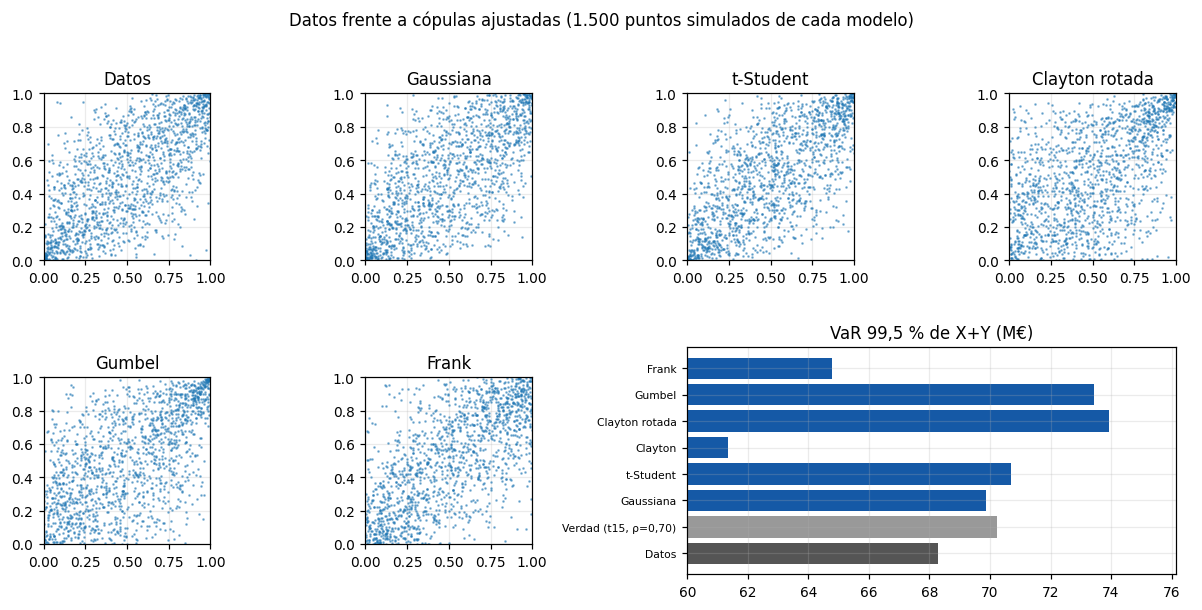

In [14]:
g2 = np.random.default_rng(8)
fig, axs = plt.subplots(2, 4, figsize=(11, 5.6))
names = ["Datos", "Gaussiana", "t-Student", "Clayton rotada", "Gumbel", "Frank"]
for ax, name in zip(axs.ravel(), names):
    U = Uh if name == "Datos" else sim_model(name, g2, n)
    ax.plot(U[:, 0], U[:, 1], ".", ms=1.5, alpha=.5); ax.set_title(name); ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
gs_ = axs[1, 2].get_gridspec()
for a in axs[1, 2:]: a.remove()
ax = fig.add_subplot(gs_[1, 2:]); lab = list(res.index)
ax.barh(range(len(lab)), res["VaR 99,5 %"], color=["#555", "#999"] + ["#1559A6"] * 6); ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab, fontsize=7)
ax.set_xlim(60, res["VaR 99,5 %"].max() * 1.03); ax.set_title("VaR 99,5 % de X+Y (M€)")
fig.suptitle("Datos frente a cópulas ajustadas (1.500 puntos simulados de cada modelo)"); fig.tight_layout(); plt.show()

## (F) Más de dos riesgos: cuatro módulos de SCR
$SCR=\sqrt{\sum_{ij}\rho_{ij}SCR_iSCR_j}=70$ M€. Se compara con cinco cópulas de **igual** $\tau$ medio (0,163): Gaussiana(P), t(ν=4) y t(ν=10) con la misma P, Clayton rotada y Gumbel (un único θ, intercambiables), con $10^6$ escenarios.

In [15]:
S = np.array([40, 30, 20, 10.]); P = np.array([[1, .25, .25, .25], [.25, 1, .5, 0], [.25, .5, 1, .25], [.25, 0, .25, 1]])
print("Autovalores de P:", np.round(np.linalg.eigvalsh(P), 3), "· SCR fórmula estándar =", round(scr_gauss(S, P), 4), "· suma simple =", S.sum())
iu = np.triu_indices(4, 1); tau_m = np.mean(2 / np.pi * np.arcsin(P[iu])); th_c4 = th_clayton(tau_m); th_g4 = th_gumbel(tau_m)
print(f"τ medio = {tau_m:.4f}  ->  Clayton θ = {th_c4:.3f}, Gumbel θ = {th_g4:.3f}")
Ch = np.linalg.cholesky(P)
def u_gauss(n, g): return stats.norm.cdf(g.standard_normal((n, 4)) @ Ch.T)
def u_t(n, nu, g): return stats.t.cdf((g.standard_normal((n, 4)) @ Ch.T) / np.sqrt(g.chisquare(nu, n) / nu)[:, None], nu)
def agg(U):
    L = (stats.norm.ppf(U) * (S / z995)).sum(axis=1); v, t = var_tvar(L); ex = (U > .99).sum(axis=1)
    return dict(VaR=v, TVaR=t, P2=np.mean(ex >= 2), P4_x100k=np.mean(ex == 4) * 1e5)
g4 = np.random.default_rng(4); NN = 1_000_000
mods = {"Gaussiana(P)": u_gauss(NN, g4), "t ν=4": u_t(NN, 4, g4), "t ν=10": u_t(NN, 10, g4), "Clayton rotada": rot(r_clayton(NN, th_c4, 4, g4)), "Gumbel": r_gumbel(NN, th_g4, 4, g4)}
out = pd.DataFrame({k: agg(U) for k, U in mods.items()}).T; out["VaR vs 70"] = out.VaR / 70 - 1
print(out.to_string(float_format=lambda x: f"{x:,.3f}"))
print("\n(P2 = P(≥2 módulos por encima de su percentil 99 a la vez); P4_x100k = casos de los 4 a la vez por 100.000 escenarios)")

Autovalores de P: [0.432 0.75  1.035 1.783] · SCR fórmula estándar = 70.0 · suma simple = 100.0
τ medio = 0.1628  ->  Clayton θ = 0.389, Gumbel θ = 1.194


                  VaR   TVaR    P2  P4_x100k  VaR vs 70
Gaussiana(P)   69.918 78.383 0.003     0.800     -0.001
t ν=4          75.992 88.251 0.007    23.700      0.086
t ν=10         72.451 83.114 0.005     5.700      0.035
Clayton rotada 81.780 94.564 0.008    41.500      0.168
Gumbel         84.318 98.237 0.005   127.200      0.205

(P2 = P(≥2 módulos por encima de su percentil 99 a la vez); P4_x100k = casos de los 4 a la vez por 100.000 escenarios)


In [16]:
# P debe ser semidefinida positiva: matriz de correlación más cercana (Higham, 2002) para el ejemplo (0,9; 0,9; −0,9)
def nearest_corr(A, it=200):
    Y_ = A.copy(); dS = np.zeros_like(A)
    for _ in range(it):
        R = Y_ - dS; w, V = np.linalg.eigh(R); X_ = (V * np.maximum(w, 0)) @ V.T; dS = X_ - R; Y_ = X_.copy(); np.fill_diagonal(Y_, 1)
    return Y_
Pb = np.array([[1, .9, .9], [.9, 1, -.9], [.9, -.9, 1]])
print("Autovalores de la matriz (0,9; 0,9; −0,9):", np.round(np.linalg.eigvalsh(Pb), 3))
Pn = nearest_corr(Pb); print("Matriz más cercana, autovalores:", np.round(np.linalg.eigvalsh(Pn), 4)); print(np.round(Pn, 3))
# volumen de W_3(u) = max(u1+u2+u3-2, 0) sobre el cubo [1/2,1]^3 (debe ser >= 0 para ser cópula): es negativo
vol = sum((-1) ** (3 - sum(c)) * max(sum(1.0 if ci else .5 for ci in c) - 2, 0) for c in np.ndindex(2, 2, 2))
print("Volumen de W_3 en [1/2,1]^3 =", vol, "(negativo: W_d no es cópula si d ≥ 3)")

Autovalores de la matriz (0,9; 0,9; −0,9): [-0.8  1.9  1.9]
Matriz más cercana, autovalores: [0.  1.5 1.5]
[[ 1.   0.5  0.5]
 [ 0.5  1.  -0.5]
 [ 0.5 -0.5  1. ]]
Volumen de W_3 en [1/2,1]^3 = -0.5 (negativo: W_d no es cópula si d ≥ 3)


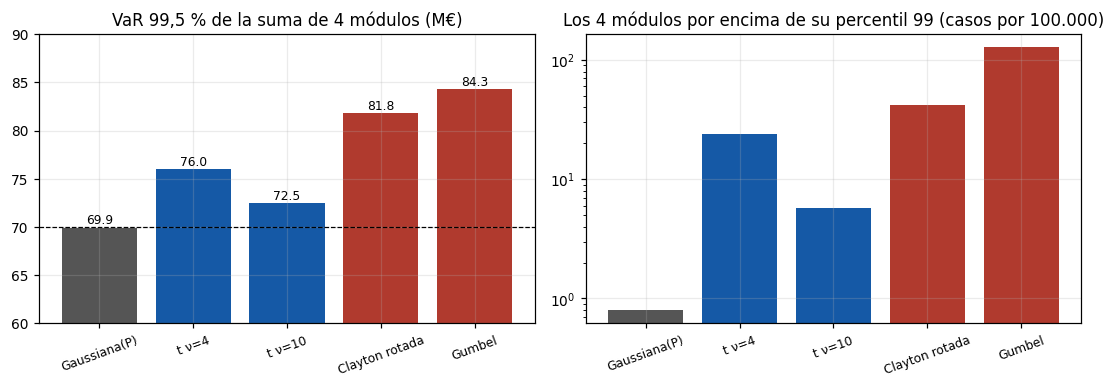

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6)); cols = ["#555", "#1559A6", "#1559A6", "#B03A2E", "#B03A2E"]
axs[0].bar(range(5), out.VaR, color=cols); axs[0].axhline(70, ls="--", c="k", lw=.8); axs[0].set_xticks(range(5)); axs[0].set_xticklabels(out.index, rotation=20, fontsize=8)
axs[0].set_ylim(60, 90); axs[0].set_title("VaR 99,5 % de la suma de 4 módulos (M€)")
for i, v in enumerate(out.VaR): axs[0].text(i, v + .4, f"{v:.1f}", ha="center", fontsize=8)
axs[1].bar(range(5), out.P4_x100k, color=cols); axs[1].set_yscale("log"); axs[1].set_xticks(range(5)); axs[1].set_xticklabels(out.index, rotation=20, fontsize=8)
axs[1].set_title("Los 4 módulos por encima de su percentil 99 (casos por 100.000)"); fig.tight_layout(); plt.show()

## (G) Apoyo cuantitativo a las preguntas de repaso y de debate
G1: ρ = 0 con λ > 0 (repaso 1) · G2: ¿en qué sentido la fórmula estándar es «Gaussiana»? (repaso 2) · G3: cuál es la familia correcta con colas asimétricas (repaso 3) ·
G4: reparto del capital adicional (debate 2) · G5: ¿se puede validar la cola con pocos datos? potencia de la selección y IC de λ (debate 3).

In [18]:
# G1) t-Student con ρ = 0: Pearson = Spearman = τ = 0 y, sin embargo, dependencia de cola
g1 = np.random.default_rng(61); U0 = r_t(2_000_000, 0.0, 4, g1)
print("t(ρ=0, ν=4): Pearson de (Φ⁻¹(U1), Φ⁻¹(U2)) =", round(np.corrcoef(stats.norm.ppf(U0[:200000, 0]), stats.norm.ppf(U0[:200000, 1]))[0, 1], 4),
      " Spearman =", round(stats.spearmanr(U0[:200000, 0], U0[:200000, 1])[0], 4), " τ =", round(stats.kendalltau(U0[:20000, 0], U0[:20000, 1])[0], 4))
print(f"λ teórico (ρ=0, ν=4) = 2·t5(−√5) = {lam_t(0.0, 4):.4f};   ν=10: {lam_t(0.0, 10):.4f};   ν=15: {lam_t(0.0, 15):.4f}")
for q in (.95, .99, .999):
    print(f"q = {q}: P(V>q|U>q) = {lam_emp(U0, q):.4f}  frente a {1-q:.3f} si fueran independientes  (razón ×{lam_emp(U0, q)/(1-q):.1f})")
sd_m_, sd_u_ = 40 / z995, 30 / z995
Lt0 = stats.norm.ppf(U0[:, 0]) * sd_m_ + stats.norm.ppf(U0[:, 1]) * sd_u_
print(f"Capital con marginales normales: independencia (ρ=0) = 50,00; cópula t(ρ=0, ν=4): VaR99,5 = {np.quantile(Lt0, .995):.2f} ({np.quantile(Lt0, .995)/50-1:+.1%})")

t(ρ=0, ν=4): Pearson de (Φ⁻¹(U1), Φ⁻¹(U2)) = 0.0021  Spearman = 0.0007  τ = -0.0002
λ teórico (ρ=0, ν=4) = 2·t5(−√5) = 0.0756;   ν=10: 0.0069;   ν=15: 0.0010
q = 0.95: P(V>q|U>q) = 0.1271  frente a 0.050 si fueran independientes  (razón ×2.5)
q = 0.99: P(V>q|U>q) = 0.0930  frente a 0.010 si fueran independientes  (razón ×9.3)
q = 0.999: P(V>q|U>q) = 0.0820  frente a 0.001 si fueran independientes  (razón ×82.0)


Capital con marginales normales: independencia (ρ=0) = 50,00; cópula t(ρ=0, ν=4): VaR99,5 = 54.97 (+9.9%)


In [19]:
# G2) ¿En qué sentido es «Gaussiana» la fórmula estándar?  SCR = 55,68
Pm = np.array([[1, .25], [.25, 1]]); S2 = np.array([40., 30.]); NG = 2_000_000; g2_ = np.random.default_rng(62)
Z2 = g2_.standard_normal((NG, 2)) @ np.linalg.cholesky(Pm).T
print(f"Formula estándar: {scr_gauss(S2, Pm):.2f}")
print(f"(a) Normal multivariante (marginales normales + cópula Gaussiana):     VaR99,5 = {np.quantile((Z2 * S2 / z995).sum(1), .995):.2f}  -> exacto")
Tm = Z2 / np.sqrt(g2_.chisquare(4, NG) / 4)[:, None]; q4 = stats.t.ppf(.995, 4)
print(f"(b) t multivariante ν=4 (elíptica; marginales t, cópula t):             VaR99,5 = {np.quantile((Tm * S2 / q4).sum(1), .995):.2f}  -> también exacto (familia elíptica)")
Ut4 = stats.t.cdf(Tm, 4)
print(f"(c) cópula t(ν=4) con marginales NORMALES (no elíptica):                 VaR99,5 = {np.quantile((stats.norm.ppf(Ut4) * S2 / z995).sum(1), .995):.2f}")
Ug = stats.norm.cdf(Z2)
for nm, sig in (("lognormal σ=0,8", .8), ("lognormal σ=1,2", 1.2)):
    c = S2 / np.exp(sig * z995)
    print(f"(d) cópula Gaussiana ρ=0,25 + marginales {nm}:               VaR99,5 = {np.quantile((np.exp(sig * stats.norm.ppf(Ug)) * c).sum(1), .995):.2f}   (suma simple = 70)")
a_ = 3.0; cp = S2 / (0.005 ** (-1 / a_) - 1)
print(f"(e) cópula Gaussiana ρ=0,25 + marginales Pareto/Lomax α=3:              VaR99,5 = {np.quantile((((1 - Ug) ** (-1 / a_) - 1) * cp).sum(1), .995):.2f}")

Formula estándar: 55.68


(a) Normal multivariante (marginales normales + cópula Gaussiana):     VaR99,5 = 55.75  -> exacto


(b) t multivariante ν=4 (elíptica; marginales t, cópula t):             VaR99,5 = 56.02  -> también exacto (familia elíptica)


(c) cópula t(ν=4) con marginales NORMALES (no elíptica):                 VaR99,5 = 59.80


(d) cópula Gaussiana ρ=0,25 + marginales lognormal σ=0,8:               VaR99,5 = 54.38   (suma simple = 70)


(d) cópula Gaussiana ρ=0,25 + marginales lognormal σ=1,2:               VaR99,5 = 53.90   (suma simple = 70)


(e) cópula Gaussiana ρ=0,25 + marginales Pareto/Lomax α=3:              VaR99,5 = 54.36


In [20]:
# G3) Con colas asimétricas la familia importa: datos con cola superior (Gumbel θ=1,8, n=1.500) y selección por AIC
def fit_all(U):
    out = {}
    out["Gaussiana"] = mle1(ll_gauss, .01, .99, U)[1]
    (rr, nn), ltt = mle_t(U); out["t-Student"] = ltt - 0  # logLik
    out["Clayton"] = mle1(ll_clayton, .01, 20, U)[1]; out["Clayton rotada"] = mle1(ll_clayton, .01, 20, 1 - U)[1]
    out["Gumbel"] = mle1(ll_gumbel, 1.0001, 20, U)[1]; out["Frank"] = mle1(ll_frank, .01, 40, U)[1]
    k = {"t-Student": 2}; return {a: -2 * b + 2 * k.get(a, 1) for a, b in out.items()}, (rr, nn)
g3 = np.random.default_rng(63); res3 = {}; nus = {}
for nm, U in (("Datos Gumbel θ=1,8", pobs(r_gumbel(1500, 1.8, rng=g3))), ("Datos Clayton rot. θ=1,2", pobs(rot(r_clayton(1500, 1.2, rng=g3)))), ("Datos Gaussianos ρ=0,68", pobs(r_gauss(1500, .68, g3)))):
    aic, (rr, nn) = fit_all(U); res3[nm] = aic; nus[nm] = nn
tab3 = pd.DataFrame(res3).round(1); tab3.loc["ν̂ de la t"] = [round(nus[c], 1) for c in tab3.columns]
print("AIC (menor = mejor):"); print(tab3.to_string())

AIC (menor = mejor):
                Datos Gumbel θ=1,8  Datos Clayton rot. θ=1,2  Datos Gaussianos ρ=0,68
Gaussiana                   -861.1                    -512.8                   -888.3
t-Student                   -886.0                    -534.1                   -885.3
Clayton                     -510.6                    -187.2                   -644.6
Clayton rotada              -880.7                    -737.2                   -660.8
Gumbel                      -944.1                    -685.4                   -795.7
Frank                       -803.1                    -484.0                   -819.2
ν̂ de la t                     8.2                       7.8                    128.6


In [21]:
# G4) Reparto del capital entre mercado y suscripción: contribución por TVaR (Euler) en la región del VaR
g4_ = np.random.default_rng(64); NE = 2_000_000
def contribuciones(U):
    mk, uw = stats.norm.ppf(U[:, 0]) * sd_m, stats.norm.ppf(U[:, 1]) * sd_u; L = mk + uw; v = np.quantile(L, .995)
    sel = np.abs(L - v) < 0.5          # entorno del VaR (±0,5 M€): esperanza condicional E[Li | L ≈ VaR]  (Euler / kernel)
    return v, mk[sel].mean(), uw[sel].mean(), sel.sum()
for nm, U in (("Gaussiana", r_gauss(NE, rho, g4_)), ("Clayton rotada", rot(r_clayton(NE, th_c, rng=g4_)))):
    v, a_m, a_u, k_ = contribuciones(U); print(f"{nm:15s} VaR = {v:.2f}   contribución mercado = {a_m:.2f} ({a_m/v:.1%})   suscripción = {a_u:.2f} ({a_u/v:.1%})   [{k_} escenarios en el entorno del VaR]")
print(f"Coste anual del capital adicional de {scr*rec:.2f} M€ al 6 % (tasa de coste de capital de Solvencia II): {0.06*scr*rec:.3f} M€")

Gaussiana       VaR = 55.71   contribución mercado = 34.20 (61.4%)   suscripción = 21.48 (38.6%)   [1300 escenarios en el entorno del VaR]


Clayton rotada  VaR = 62.07   contribución mercado = 36.61 (59.0%)   suscripción = 25.46 (41.0%)   [1085 escenarios en el entorno del VaR]
Coste anual del capital adicional de 7.24 M€ al 6 % (tasa de coste de capital de Solvencia II): 0.434 M€


In [22]:
# G5) ¿Se puede validar la cola con pocos datos?  (i) IC bootstrap de λ(q) en la muestra; (ii) potencia de AIC para distinguir t de la Gaussiana
gb5 = np.random.default_rng(65)
bs = {q: [] for q in (.90, .95, .99)}
for _ in range(1000):
    ix = gb5.integers(0, n, n); Ub = pobs(np.c_[X[ix], Y[ix]])
    for q in bs: bs[q].append(lam_emp(Ub, q))
print("IC 95 % bootstrap de P(V>q|U>q) en la muestra (n=1.500):")
for q in bs: print(f"  q = {q}: estimador {lam_emp(Uh, q):.3f}   IC [{np.percentile(bs[q], 2.5):.3f}; {np.percentile(bs[q], 97.5):.3f}]   puntos en la cola: {int(round(n*(1-q)))}")
def aic_gap(U):                      # AIC(Gaussiana) − AIC(t): positivo => se elige la t
    rg_, lg_ = mle1(ll_gauss, .01, .99, U); (rt_, nt_), lt__ = mle_t(U); return (-2 * lg_ + 2) - (-2 * lt__ + 4)
pot = []
for nn_, nu_ in ((250, 15), (1500, 15), (250, 4), (1500, 4), (1500, 1e6)):
    ch = 0; R_ = 60
    for _ in range(R_):
        Ub = pobs(r_t(nn_, .7, nu_, gb5) if nu_ < 1e5 else r_gauss(nn_, .7, gb5)); ch += aic_gap(Ub) > 0
    pot.append((nn_, "Gaussiana (verdad)" if nu_ > 1e5 else f"t ν={nu_}", ch / R_))
print("\nFracción de réplicas (60) en que el AIC elige la t frente a la Gaussiana:")
print(pd.DataFrame(pot, columns=["n", "proceso generador", "AIC elige t"]).to_string(index=False))

IC 95 % bootstrap de P(V>q|U>q) en la muestra (n=1.500):
  q = 0.9: estimador 0.467   IC [0.407; 0.544]   puntos en la cola: 150
  q = 0.95: estimador 0.360   IC [0.253; 0.453]   puntos en la cola: 75
  q = 0.99: estimador 0.267   IC [0.067; 0.533]   puntos en la cola: 15



Fracción de réplicas (60) en que el AIC elige la t frente a la Gaussiana:


   n  proceso generador  AIC elige t
 250             t ν=15     0.466667
1500             t ν=15     1.000000
 250              t ν=4     0.983333
1500              t ν=4     1.000000
1500 Gaussiana (verdad)     0.100000
